# Part 3: Pipelines and Text Data – Medical Aid Customer Review Analysis

## 1. Introduction and Business Problem

The purpose of this analysis is to identify the main concerns raised by customers in online reviews and assess the sentiment expressed towards healthcare cover providers. The study uses customer reviews from the HelloPeter dataset, focusing on Bonitas Medical Fund and Affinity Health.

Two natural language processing approaches are applied. Latent Dirichlet Allocation (LDA) topic modelling is used to identify recurring themes in customer reviews, while VADER sentiment analysis is used to classify reviews as positive, negative or neutral.

The findings are intended to help the client understand frequently discussed service issues, assess customer experiences and identify areas requiring further investigation. The analysis is exploratory and does not assume that online reviewers represent the entire customer population.

## 2. Dataset Selection, Suitability and Quality

The analysis uses a publicly available dataset titled Business Reviews from different Industries, obtained from Kaggle and uploaded by Ashlin Darius Govindasamy. According to the dataset description, the reviews were collected from the South African consumer review platform Hello Peter using its application programming interface (API). The dataset contains customer reviews from different business industries, including written feedback and ratings ranging from one to five stars. For this study, reviews relating to Bonitas Medical Fund and Affinity Health were selected because they provide healthcare-related customer feedback suitable for topic modelling and sentiment analysis.

The analysis focuses on Bonitas Medical Fund and Affinity Health because both provide healthcare-related financial protection services in South Africa. However, Bonitas is a registered medical scheme, whereas Affinity Health offers health insurance products. Their different operating models must be considered when interpreting comparisons.

### 2.1 Suitability for the Selected Models

**Latent Dirichlet Allocation (LDA):** The dataset contains unstructured review text that can be transformed into numerical word-frequency features. This allows LDA to identify recurring themes such as claims, communication, healthcare benefits and membership-related concerns without requiring manually labelled topics.

**VADER sentiment analysis:** The reviews contain expressions of satisfaction, frustration and dissatisfaction. VADER can assign sentiment polarity scores to these texts without requiring a manually labelled training dataset. The available star ratings also provide an approximate reference for evaluating agreement between predicted sentiment and customer ratings.

### 2.2 Data Quality and Limitations

Several potential data-quality issues must be considered:

- **Missing information:** Reviews with missing or unusable text may not contribute meaningfully to the analysis.
- **Duplicate reviews:** Repeated records could overrepresent particular experiences and should be checked during cleaning.
- **Unstructured language:** Spelling mistakes, punctuation, HTML tags and informal expressions can affect text processing.
- **Selection bias:** Customers who post online reviews may not represent the entire customer population.
- **Rating–text disagreement:** A review's star rating may not fully reflect the sentiment expressed in its written content.
- **Historical coverage:** The dataset represents experiences recorded during its collection period and cannot establish current customer sentiment.
- **Provider differences:** The two organisations offer different types of healthcare cover, limiting direct comparisons.

These limitations are considered when preparing the data, evaluating model performance and interpreting the findings.

The data-quality assessment identified no duplicate records among the 4,966 selected reviews. All reviews contained non-missing review text, although two records had missing review titles. Since the analysis primarily used review content rather than titles, these records were retained. No invalid review dates were identified. The reviews covered the period from 28 January 2015 to 17 December 2022. Following text preprocessing, 134 reviews contained fewer than five cleaned words and were excluded from LDA topic modelling, leaving 4,832 reviews. All 4,966 reviews were retained for VADER sentiment analysis.

## 3. Model Selection and Justification

Two complementary natural language processing approaches were selected to address the client's objectives: Latent Dirichlet Allocation (LDA) for topic modelling and Valence Aware Dictionary and sEntiment Reasoner (VADER) for sentiment analysis. These methods answer different questions: LDA identifies what customers discuss, while VADER estimates how positively or negatively they express their experiences.

### 3.1 Latent Dirichlet Allocation (LDA)

LDA is an unsupervised probabilistic topic modelling algorithm that identifies patterns of word co-occurrence across documents (Blei, Ng and Jordan, 2003). It represents each review as a mixture of topics and each topic as a distribution of words.

LDA was selected because the reviews do not contain manually assigned topic labels. It allows recurring concerns to be explored without first developing a labelled training dataset. The model also produces interpretable lists of representative words, which can be examined to assign meaningful topic descriptions.

**Comparison with alternative methods:** Non-negative Matrix Factorisation (NMF) is another suitable topic modelling technique that can produce interpretable topics from document-term matrices. However, LDA was preferred because its probabilistic representation supports the examination of topic mixtures within individual reviews. More advanced embedding-based approaches, such as BERTopic, can capture semantic similarities that word-frequency models may miss, but require additional computational resources and more complex model configuration.

LDA has limitations. Its results depend on preprocessing choices and the selected number of topics. Reviews are often short, and topics may overlap or contain ambiguous words. Consequently, topic quality must be evaluated using quantitative measures and qualitative inspection of representative words and reviews.

### 3.2 VADER Sentiment Analysis

VADER is a rule-based, lexicon-based sentiment analysis method designed to account for sentiment-bearing words and linguistic features such as capitalisation, punctuation and intensifiers (Hutto and Gilbert, 2014).

VADER was selected because it can analyse review sentiment without requiring manually labelled training examples. Its compound score provides a consistent numerical basis for assigning positive, negative and neutral sentiment categories.

**Comparison with alternative methods:** TextBlob is another lexicon-based option, but VADER was preferred because it explicitly incorporates several linguistic features common in informal online text. Supervised classifiers, such as logistic regression and support vector machines, could learn patterns specific to medical aid reviews, but would require reliable labelled training data. Transformer-based models, such as BERT, may capture contextual meaning more effectively but introduce greater computational and implementation complexity.

VADER also has limitations. It may misinterpret sarcasm, mixed sentiment, domain-specific expressions and lengthy complaints containing positive words. Its predictions are therefore compared with sentiment categories derived from review ratings. These ratings are treated as approximate reference labels rather than definitive measures of the sentiment expressed in the text.

### 3.3 Complementary Use of Both Models

LDA and VADER are used together because neither method independently addresses both client objectives. LDA identifies recurring discussion themes, while VADER estimates sentiment polarity. Their combined findings can help prioritise issues for further investigation, although neither method establishes the prevalence of problems across the entire customer population.



## 4. Analysis Plan

The analysis follows a structured approach to identify recurring customer concerns and assess sentiment in reviews of Bonitas Medical Fund and Affinity Health. The following stages guide the Python implementation.

| Stage | Planned activities | Purpose |
|---|---|---|
| 1. Data inspection and cleaning | Examine the dataset's structure, missing values, duplicate records, review ratings and text quality. Remove unusable records and prepare review text for analysis. | Improve data quality and reduce misleading results. |
| 2. Exploratory Data Analysis (EDA) | Examine review volumes, rating distributions, review lengths, frequently occurring terms and differences between providers. | Understand the dataset and identify patterns relevant to modelling. |
| 3. Feature extraction | Use cleaned review text to construct a document-term matrix for topic modelling. Retain suitable words and exclude uninformative terms. | Represent textual information numerically while reducing noise. |
| 4. Topic modelling | Apply Latent Dirichlet Allocation (LDA) to identify recurring themes. Examine topic keywords and representative reviews, and assess alternative topic configurations. | Identify broad areas discussed by customers. |
| 5. Sentiment analysis | Apply VADER to review text and classify sentiment as positive, negative or neutral using compound sentiment scores. | Estimate the sentiment expressed in customer reviews. |
| 6. Model evaluation | Assess LDA using test perplexity across different topic configurations and qualitative interpretation of topic keywords and representative reviews. Evaluate VADER using accuracy, precision, recall, F1-score and a confusion matrix against rating-derived sentiment labels. | Evaluate the usefulness and limitations of both approaches. |
| 7. Error analysis and reporting | Examine sentiment disagreements, compare findings across providers and explain the main results through tables, visualisations and written interpretations. | Provide understandable findings and identify areas requiring further investigation. |

### 4.1 Additional Methodological Considerations

**Data preparation:** Text cleaning will account for missing information, duplicate reviews, HTML formatting, punctuation and irrelevant terms. Preprocessing will be adapted to the model: topic modelling requires removal of uninformative words, while sentiment analysis must preserve expressions such as negation that influence emotional meaning.

**Model configuration:** LDA will be assessed using alternative topic counts and suitable document-term features. Topic selection will consider both quantitative measures and whether the resulting themes can be meaningfully interpreted. VADER will use its established compound-score thresholds because it is a pretrained, rule-based sentiment analyser rather than a model trained from scratch on this dataset.

**Evaluation limitations:** Star ratings provide an approximate reference for evaluating sentiment predictions, not independently verified sentiment labels. Disagreement between ratings and review text may reflect ambiguous language, mixed experiences or limitations of the sentiment analyser.

**Comparability:** The same core preprocessing and analysis procedures will be applied consistently to both providers. However, Bonitas Medical Fund and Affinity Health offer different healthcare financing products, so comparisons will be interpreted cautiously.

**Reporting:** Findings will be presented as exploratory evidence from the available online reviews. They will not be generalised to all customers or treated as proof of current service performance.

In [1]:
import pandas as pd

# Load the HelloPeter customer reviews dataset
file_path = "rawdata.csv"

df = pd.read_csv(file_path, low_memory=False)

# Check the size and structure of the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Preview the first five records
display(df.head())

Dataset shape: (56260, 27)

Column names:
['id', 'user_id', 'created_at', 'authorDisplayName', 'author', 'authorAvatar', 'author_id', 'review_title', 'review_rating', 'review_content', 'business_name', 'business_slug', 'permalink', 'replied', 'messages', 'business_logo', 'industry_logo', 'industry_name', 'industry_slug', 'status_id', 'nps_rating', 'source', 'is_reported', 'business_reporting', 'author_created_date', 'author_total_reviews_count', 'attachments']


,id,user_id,created_at,authorDisplayName,author,authorAvatar,author_id,review_title,review_rating,review_content,...,industry_name,industry_slug,status_id,nps_rating,source,is_reported,business_reporting,author_created_date,author_total_reviews_count,attachments
0,4228893,0cf37140-f94c-11ec-9b49-19cd672a8c8b,2022-12-16 20:51:27,Werner S,Werner S,NaN,0cf37140-f94c-11ec-9b49-19cd672a8c8b,Not telkpm,1,I pay R519 per month and can't signin on the ...,...,Telecommunications,telecommunications,1,NaN,WEBSITE,False,NaN,2022-07-01,3,[]
1,4228846,364faaf0-5104-11ec-8045-7d7a9af8c558,2022-12-16 18:54:28,Nokuthula K,Nokuthula K,NaN,364faaf0-5104-11ec-8045-7d7a9af8c558,Please help me clear my name,1,I can't even buy a house because telkom failed...,...,Telecommunications,telecommunications,1,NaN,WEBSITE,False,NaN,2021-11-29,3,[]
2,4228766,0c8502a0-5ee0-11ea-9899-6f17cff30ea1,2022-12-16 16:28:46,Services A,Services A,NaN,0c8502a0-5ee0-11ea-9899-6f17cff30ea1,Untrustworthy business,1,I was contacted if I wanted to upgrade a data ...,...,Telecommunications,telecommunications,1,NaN,WEBSITE,False,NaN,2020-03-05,50,[]
3,4228626,35bf64d7-31fa-11e8-83f4-f23c91bb6188,2022-12-16 12:58:01,Nina H,Nina H,NaN,35bf64d7-31fa-11e8-83f4-f23c91bb6188,telkom,1,Have been in a fight with TELKOM since August ...,...,Telecommunications,telecommunications,1,NaN,WEBSITE,False,NaN,2017-05-06,1,[]
4,4228610,2b490ce9-31fa-11e8-83f4-f23c91bb6188,2022-12-16 12:42:24,Arshad P,Arshad P,NaN,2b490ce9-31fa-11e8-83f4-f23c91bb6188,TELKOM Killarney Looting on Upgrade,1,"-10, \nSo I have Telkom contract with Telkom f...",...,Telecommunications,telecommunications,1,NaN,WEBSITE,False,NaN,2016-07-01,5,[]


In [2]:
# Filter the dataset to include only Medical Aid reviews
medical_aid_df = df[
    df["industry_name"] == "Medical Aid"
].copy()

# Select the columns relevant to our analysis
medical_aid_df = medical_aid_df[
    [
        "created_at",
        "business_name",
        "review_title",
        "review_content",
        "review_rating"
    ]
].copy()

# Display the number of medical aid reviews
print("Medical Aid dataset shape:", medical_aid_df.shape)

# Count reviews for each medical aid provider
print("\nReviews per medical aid provider:")
print(medical_aid_df["business_name"].value_counts())

# Display the first five records
display(medical_aid_df.head())


Medical Aid dataset shape: (4966, 5)

Reviews per medical aid provider:
business_name
Bonitas Medical Fund    2721
Affinity Health         2245
Name: count, dtype: int64


,created_at,business_name,review_title,review_content,review_rating
25909,2022-12-12 08:14:49,Affinity Health,Customer Service Unavailability on Weekends Ni...,I was extremely dissapointed! I had to go get ...,1
25910,2022-12-11 09:48:49,Affinity Health,Endless waiting,The service of this medical aid is getting so ...,1
25911,2022-12-09 19:31:37,Affinity Health,Bad service,WORSE MEDICAL INSURANCE EVER!!! They cover not...,1
25912,2022-12-08 17:06:23,Affinity Health,Worst medical insurance,USELESS!!! What a waste of money. It's better ...,1
25913,2022-12-07 08:48:21,Affinity Health,STAY AWAY!,STAY AWAY!! You will spend more time pre-autho...,1


In [3]:
# STEP 3: DATA QUALITY ASSESSMENT

# Display dataset structure and data types
print("DATASET INFORMATION")
medical_aid_df.info()

# Identify missing values in each column
print("\nMISSING VALUES")
print(medical_aid_df.isnull().sum())

# Identify duplicate records
print("\nDUPLICATE RECORDS")
print(medical_aid_df.duplicated().sum())

# Check the distribution of review ratings
print("\nREVIEW RATING DISTRIBUTION")
print(
    medical_aid_df["review_rating"]
    .value_counts(dropna=False)
    .sort_index()
)

# Identify the earliest and latest review dates
medical_aid_df["created_at"] = pd.to_datetime(
    medical_aid_df["created_at"],
    errors="coerce"
)

print("\nDATE RANGE")
print("Earliest review:", medical_aid_df["created_at"].min())
print("Latest review:", medical_aid_df["created_at"].max())

# Check for invalid dates
print("\nINVALID DATES")
print(medical_aid_df["created_at"].isna().sum())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
Index: 4966 entries, 25909 to 30874
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   created_at      4966 non-null   object
 1   business_name   4966 non-null   object
 2   review_title    4964 non-null   object
 3   review_content  4966 non-null   object
 4   review_rating   4966 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 232.8+ KB

MISSING VALUES
created_at        0
business_name     0
review_title      2
review_content    0
review_rating     0
dtype: int64

DUPLICATE RECORDS
0

REVIEW RATING DISTRIBUTION
review_rating
1    1729
2    1085
3     102
4     331
5    1719
Name: count, dtype: int64

DATE RANGE
Earliest review: 2015-01-28 11:20:00
Latest review: 2022-12-17 08:27:54

INVALID DATES
0


RATING DISTRIBUTION BY MEDICAL AID PROVIDER


,business_name,review_rating,count,percentage
0,Affinity Health,1,629,28.017817
1,Affinity Health,2,149,6.636971
2,Affinity Health,3,36,1.603563
3,Affinity Health,4,331,14.743875
4,Affinity Health,5,1100,48.997773
5,Bonitas Medical Fund,1,1100,40.426314
6,Bonitas Medical Fund,2,936,34.399118
7,Bonitas Medical Fund,3,66,2.425579
8,Bonitas Medical Fund,5,619,22.748989


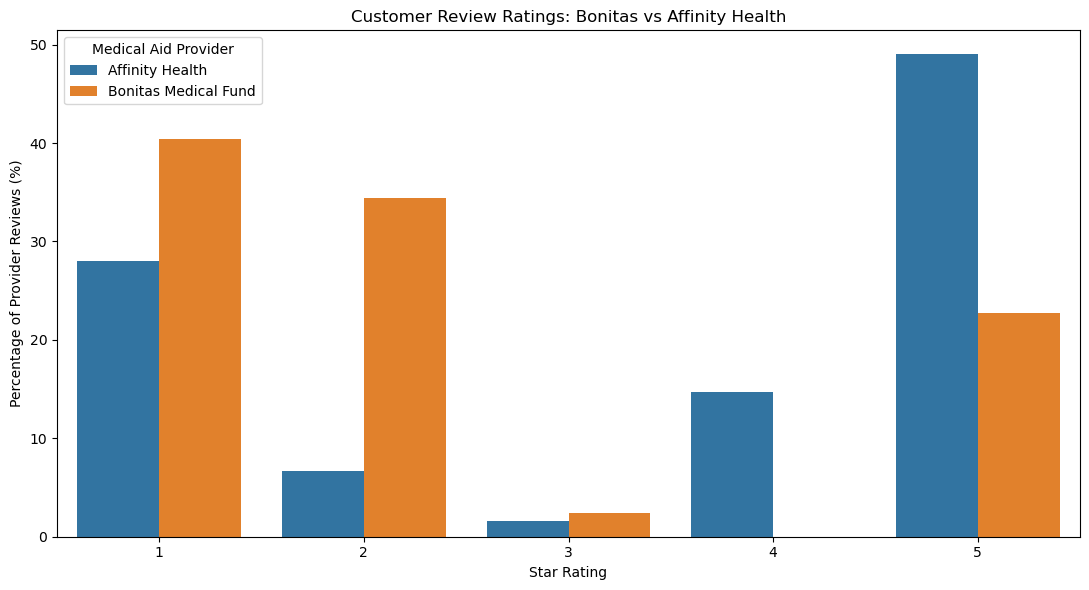

In [4]:
# STEP 4: EXPLORATORY DATA ANALYSIS
# Compare customer review ratings across the two medical aid providers

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Count reviews for each provider and star rating
rating_counts = (
    medical_aid_df
    .groupby(["business_name", "review_rating"])
    .size()
    .reset_index(name="count")
)

# Calculate percentages within each provider
rating_counts["percentage"] = (
    rating_counts["count"]
    / rating_counts.groupby("business_name")["count"].transform("sum")
    * 100
)

# Display the summary table
print("RATING DISTRIBUTION BY MEDICAL AID PROVIDER")
display(rating_counts)

# Plot percentage distribution for fair comparison
plt.figure(figsize=(11, 6))

sns.barplot(
    data=rating_counts,
    x="review_rating",
    y="percentage",
    hue="business_name"
)

plt.title("Customer Review Ratings: Bonitas vs Affinity Health")
plt.xlabel("Star Rating")
plt.ylabel("Percentage of Provider Reviews (%)")
plt.legend(title="Medical Aid Provider")
plt.tight_layout()
plt.show()


### Interpretation of Review Rating Distribution

The analysis reveals substantial differences in customer ratings between the two healthcare providers. Bonitas Medical Fund received a higher proportion of negative ratings (approximately 74.8%) compared with Affinity Health (34.7%). Conversely, positive ratings accounted for approximately 63.7% of Affinity Health reviews, compared with 22.7% for Bonitas Medical Fund.

These findings suggest that dissatisfaction is more prominent in the Bonitas reviews included in the dataset. However, the results should not be interpreted as a definitive comparison of service quality because online reviews may be influenced by self-selection bias, differences in customer characteristics and the historical period covered.

The differences also justify examining customer concerns separately for each provider during subsequent topic modelling.

OVERALL REVIEW LENGTH STATISTICS
count    4966.000000
mean       90.080548
std        95.834777
min         1.000000
25%        23.000000
50%        60.000000
75%       129.000000
max      1687.000000
Name: review_length, dtype: float64

REVIEW LENGTH STATISTICS BY PROVIDER


,count,mean,std,min,25%,50%,75%,max
business_name,,,,,,,,
Affinity Health,2245.0,63.845880,84.390154,1.0,15.0,31.0,77.0,783.0
Bonitas Medical Fund,2721.0,111.725836,99.260137,1.0,43.0,91.0,160.0,1687.0



Reviews containing fewer than five words: 133


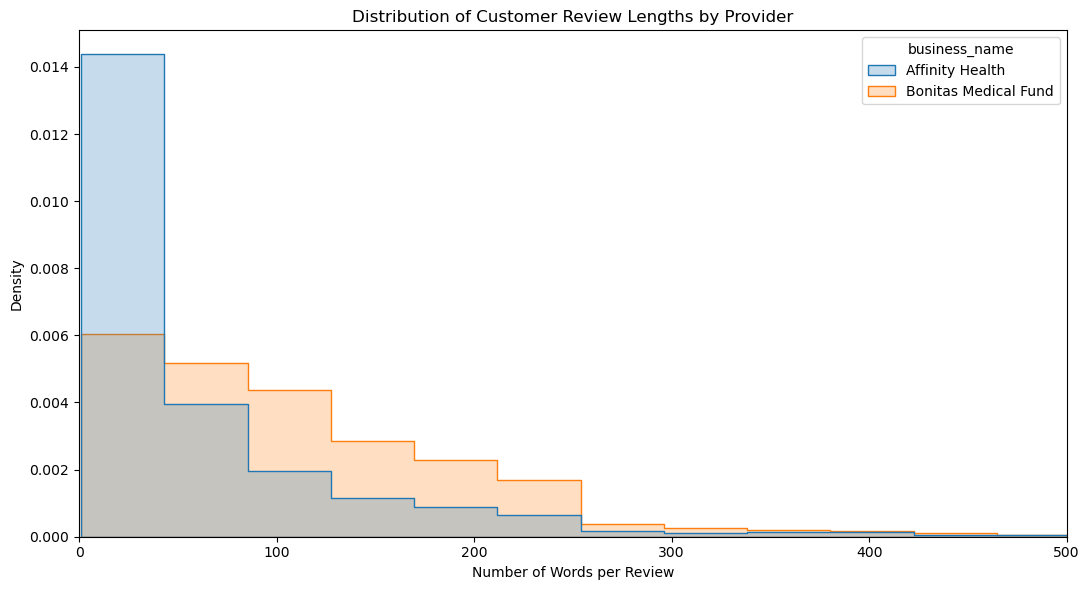

In [5]:
# STEP 5: EXPLORATORY DATA ANALYSIS - REVIEW LENGTHS

# Calculate the number of words in each review
medical_aid_df["review_length"] = (
    medical_aid_df["review_content"]
    .astype(str)
    .str.split()
    .str.len()
)

# Display summary statistics
print("OVERALL REVIEW LENGTH STATISTICS")
print(medical_aid_df["review_length"].describe())

print("\nREVIEW LENGTH STATISTICS BY PROVIDER")
display(
    medical_aid_df.groupby("business_name")["review_length"].describe()
)

# Count very short reviews
short_reviews = (medical_aid_df["review_length"] < 5).sum()
print("\nReviews containing fewer than five words:", short_reviews)

# Plot review length distribution by provider
plt.figure(figsize=(11, 6))

sns.histplot(
    data=medical_aid_df,
    x="review_length",
    hue="business_name",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlim(0, 500)
plt.title("Distribution of Customer Review Lengths by Provider")
plt.xlabel("Number of Words per Review")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


### Interpretation of Review Length Distribution

The exploratory analysis indicates that customer review lengths vary considerably across the dataset. Reviews contain an average of approximately 90 words, with a median of 60 words. The distribution is positively skewed, indicating that most reviews are relatively short, while a smaller number contain extensive descriptions of customer experiences.

Bonitas Medical Fund reviews are generally longer, averaging approximately 112 words compared with 64 words for Affinity Health. This suggests that Bonitas reviewers tend to provide more detailed written feedback, although review length alone does not establish the seriousness or nature of customer concerns.

Only 133 reviews (2.7%) contain fewer than five words. These reviews may provide insufficient contextual information for reliable topic identification. Consequently, a minimum word-count threshold will be considered when preparing the LDA dataset, while retaining suitable short reviews for sentiment analysis.

In [6]:
# STEP 6A: PREPARE DATA FOR TEXT ANALYSIS

# Create a working copy of the medical aid review dataset
text_df = medical_aid_df.copy()

print("Reviews available for text analysis:", len(text_df))

Reviews available for text analysis: 4966


In [7]:
# STEP 6B: DEFINE THE TEXT CLEANING FUNCTION

import re
import html

def clean_review(text):
    # Convert text to a string and decode HTML characters
    text = html.unescape(str(text))

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs and HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove punctuation and numbers
    # Keep letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Return the cleaned text
    return text

# Test the function
print(clean_review("Terrible SERVICE!!! I waited 3 days."))


terrible service i waited days


In [8]:
# STEP 6C: APPLY TEXT CLEANING AND VALIDATE RESULTS

# Apply the corrected cleaning function to the original reviews
text_df["clean_review"] = text_df["review_content"].fillna("").apply(clean_review)

# Recalculate cleaned review lengths
text_df["clean_length"] = text_df["clean_review"].str.split().str.len()

# Check the results
print("Total reviews:", len(text_df))
print("Empty reviews after cleaning:", (text_df["clean_length"] == 0).sum())
print("Reviews with fewer than five cleaned words:",
      (text_df["clean_length"] < 5).sum())

# Confirm the cleaned text contains strings
print("\nCleaned review data types:")
print(text_df["clean_review"].map(type).value_counts())

# Display the corrected results
print("\nORIGINAL VS CLEANED REVIEWS")
display(
    text_df[
        ["business_name", "review_content", "clean_review", "clean_length"]
    ].head(10)
)


Total reviews: 4966
Empty reviews after cleaning: 0
Reviews with fewer than five cleaned words: 134

Cleaned review data types:
clean_review
<class 'str'>    4966
Name: count, dtype: int64

ORIGINAL VS CLEANED REVIEWS


,business_name,review_content,clean_review,clean_length
25909,Affinity Health,I was extremely dissapointed! I had to go get ...,i was extremely dissapointed i had to go get m...,74
25910,Affinity Health,The service of this medical aid is getting so ...,the service of this medical aid is getting so ...,173
25911,Affinity Health,WORSE MEDICAL INSURANCE EVER!!! They cover not...,worse medical insurance ever they cover nothin...,93
25912,Affinity Health,USELESS!!! What a waste of money. It's better ...,useless what a waste of money it s better not ...,31
25913,Affinity Health,STAY AWAY!! You will spend more time pre-autho...,stay away you will spend more time pre authori...,43
25914,Affinity Health,To anyone subscribing to this medical insuranc...,to anyone subscribing to this medical insuranc...,479
25915,Affinity Health,I signed up for Affinity Health and later on d...,i signed up for affinity health and later on d...,135
25916,Affinity Health,"Where do I start? Appalling service, disrespec...",where do i start appalling service disrespectf...,19
25917,Affinity Health,Bad I just wish I could cancel this days they ...,bad i just wish i could cancel this days they ...,78
25918,Affinity Health,Please do not apply for this medical insurance...,please do not apply for this medical insurance...,115


### Step 7: Feature Extraction for Topic Modelling

CountVectorizer is used to convert cleaned customer reviews into a document-term matrix containing word frequencies. Common English stop words are excluded, while unigrams and bigrams are considered to capture individual words and meaningful two-word expressions.

Terms appearing in fewer than five reviews or more than 90% of reviews are excluded to reduce noise. The vocabulary is limited to 3,000 features to keep the model computationally manageable.

Reviews containing fewer than five cleaned words are excluded from topic modelling because they may provide insufficient context for identifying meaningful topics. The original dataset is retained for sentiment analysis.

In [9]:
# STEP 7: FEATURE EXTRACTION FOR LDA TOPIC MODELLING

from sklearn.feature_extraction.text import CountVectorizer

# Keep reviews with at least five cleaned words for topic modelling
lda_df = text_df.loc[
    text_df["clean_length"] >= 5
].copy()

# Define the CountVectorizer
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=3000,
    min_df=5,
    max_df=0.90,
    ngram_range=(1, 2)
)

# Convert customer reviews into a document-term matrix
dtm = vectorizer.fit_transform(lda_df["clean_review"])

# Extract the vocabulary
feature_names = vectorizer.get_feature_names_out()

# Display results
print("Total cleaned reviews:", len(text_df))
print("Reviews retained for LDA:", len(lda_df))
print("Reviews excluded from LDA:", len(text_df) - len(lda_df))
print("Document-term matrix shape:", dtm.shape)
print("Number of vocabulary features:", len(feature_names))

print("\nFirst 30 vocabulary features:")
print(feature_names[:30])

# Check reviews retained for each provider
print("\nReviews retained by medical aid provider:")
print(lda_df["business_name"].value_counts())


Total cleaned reviews: 4966
Reviews retained for LDA: 4832
Reviews excluded from LDA: 134
Document-term matrix shape: (4832, 3000)
Number of vocabulary features: 3000

First 30 vocabulary features:
['aan' 'able' 'able assist' 'absolute' 'absolute pleasure' 'absolutely'
 'accept' 'acceptable' 'accepted' 'access' 'accident' 'according'
 'accordingly' 'account' 'account arrears' 'account bonitas'
 'account called' 'account debited' 'account number' 'account paid'
 'account suspended' 'account told' 'accountable' 'accounts'
 'accounts department' 'accumulated' 'acknowledge' 'acknowledged'
 'acknowledgement' 'act']

Reviews retained by medical aid provider:
business_name
Bonitas Medical Fund    2650
Affinity Health         2182
Name: count, dtype: int64


### Step 8: Latent Dirichlet Allocation (LDA) Topic Modelling

Latent Dirichlet Allocation (LDA) is an unsupervised machine learning algorithm used to identify underlying themes within collections of text. It assumes that each customer review can contain a mixture of topics and that each topic is represented by a probability distribution over words.

LDA is appropriate for this analysis because the HelloPeter reviews do not contain predefined complaint categories. The model can therefore help identify recurring customer concerns without requiring manually labelled training data.

An initial model with five topics is fitted using the document-term matrix. A fixed random state supports reproducibility. Model perplexity is recorded as an initial quantitative diagnostic, while topic interpretability and comparisons between different topic counts will be considered during evaluation.

In [10]:
# STEP 8: TRAIN THE LDA TOPIC MODEL

from sklearn.decomposition import LatentDirichletAllocation

# Define the initial LDA model
lda_model = LatentDirichletAllocation(
    n_components=5,
    max_iter=20,
    learning_method="batch",
    random_state=42,
    n_jobs=-1
)

# Train the LDA model
lda_model.fit(dtm)

# Display model information
print("LDA model training completed successfully.")
print("Number of topics:", lda_model.n_components)
print("Number of iterations:", lda_model.n_iter_)

# Calculate training perplexity
perplexity = lda_model.perplexity(dtm)

print("Training perplexity:", round(perplexity, 2))


LDA model training completed successfully.
Number of topics: 5
Number of iterations: 20
Training perplexity: 1041.42


### Step 9: Identification and Interpretation of LDA Topics

Following model training, the most influential words associated with each of the five topics are extracted and examined.

The purpose of this stage is to identify recurring themes in customer feedback, such as service delivery, medical claims, communication, authorisation processes and other issues, where supported by the model's results.

The topics will initially be represented by their highest-weighted words. Meaningful topic labels will subsequently be assigned based on these words and representative customer reviews, rather than assumed in advance.

In [11]:
# STEP 9: EXTRACT THE TOP WORDS FROM EACH LDA TOPIC

import pandas as pd

# Retrieve vocabulary terms from the fitted vectorizer
feature_names = vectorizer.get_feature_names_out()

# Number of important words to display per topic
n_top_words = 15

# Store the results for later analysis
topic_results = []

# Extract the highest-weighted words for each topic
for topic_index, topic in enumerate(lda_model.components_):

    # Identify the indices of the most important words
    top_indices = topic.argsort()[-n_top_words:][::-1]

    # Retrieve the corresponding vocabulary terms
    top_words = feature_names[top_indices]

    # Store topic information
    topic_results.append({
        "Topic": f"Topic {topic_index + 1}",
        "Top Words": ", ".join(top_words)
    })

# Display the topics in a readable table
topic_df = pd.DataFrame(topic_results)

print("TOP 15 WORDS FOR EACH LDA TOPIC")
display(topic_df)


TOP 15 WORDS FOR EACH LDA TOPIC


,Topic,Top Words
0,Topic 1,"bonitas, claim, service, email, sent, number, ..."
1,Topic 2,"medical, bonitas, aid, medical aid, account, m..."
2,Topic 3,"affinity, health, affinity health, medication,..."
3,Topic 4,"medical, pay, hospital, aid, medical aid, affi..."
4,Topic 5,"service, thank, great, helpful, excellent, fri..."


In [12]:
# STEP 9A: DISPLAY ALL LDA TOPIC WORDS WITHOUT TRUNCATION

for _, row in topic_df.iterrows():
    print("=" * 65)
    print(row["Topic"])
    print("=" * 65)
    print(row["Top Words"])
    print()


Topic 1
bonitas, claim, service, email, sent, number, received, response, medical, claims, query, time, paid, feedback, days

Topic 2
medical, bonitas, aid, medical aid, account, money, received, payment, membership, told, email, debit, month, sent, did

Topic 3
affinity, health, affinity health, medication, pharmacy, service, direct, pharmacy direct, chronic, just, good, time, chronic medication, company, people

Topic 4
medical, pay, hospital, aid, medical aid, affinity, cover, doctor, bonitas, told, health, need, day, year, covered

Topic 5
service, thank, great, helpful, excellent, friendly, professional, good, assisted, excellent service, assistance, thanks, great service, help, received



### Step 10: Examination of Representative Customer Reviews

The five topics identified through LDA are examined further by reviewing representative customer comments.

Although the highest-weighted words provide an initial indication of each topic's meaning, they do not fully explain the context of individual customer experiences. Examining actual reviews is therefore necessary to establish whether the topics represent meaningful service concerns.

Each review is assigned a dominant topic based on its highest estimated topic probability. Representative reviews are then selected to support the interpretation of the topics.

The resulting topic labels will remain provisional until the review content has been examined. This qualitative validation complements the quantitative evaluation of the LDA model.

In [13]:
# STEP 10: IDENTIFY DOMINANT TOPICS AND REPRESENTATIVE REVIEWS

import numpy as np
import pandas as pd

# Obtain topic probabilities for each review
topic_probabilities = lda_model.transform(dtm)

# Create a working dataset containing reviews used for LDA
topic_reviews = lda_df.copy()

# Assign the dominant topic to each review
topic_reviews["dominant_topic"] = (
    np.argmax(topic_probabilities, axis=1) + 1
)

# Record the probability of the dominant topic
topic_reviews["topic_probability"] = (
    np.max(topic_probabilities, axis=1)
)

# Display three representative reviews per topic
for topic_number in range(1, 6):

    print("\n" + "=" * 70)
    print(f"TOPIC {topic_number}")
    print("=" * 70)

    # Select reviews most strongly associated with this topic
    examples = (
        topic_reviews[
            topic_reviews["dominant_topic"] == topic_number
        ]
        .sort_values(
            "topic_probability",
            ascending=False
        )
        .head(3)
    )

    for _, row in examples.iterrows():

        print("\nProvider:", row["business_name"])
        print("Rating:", row["review_rating"])
        print(
            "Topic probability:",
            round(row["topic_probability"], 3)
        )
        print("Review:", row["review_content"][:500])
        print("-" * 70)



TOPIC 1

Provider: Bonitas Medical Fund
Rating: 1
Topic probability: 0.994
Review: As a Bonitas member, I requested membership to their Oncology benefits and only received confirmation 3 weeks after numerous emails to this regard. After the operation, I was referred to an Oncologist for post op consultation. I requested Bonitas to confirm that the Oncologist provided was contracted to the Oncologist benefits. Numerous emails were sent to this regard and when I eventually attended a consultation with the Oncologist, Bonitas indicated that only a portion of the claim will be pai
----------------------------------------------------------------------

Provider: Bonitas Medical Fund
Rating: 2
Topic probability: 0.991
Review: I send various emails regarding an application form that has been sent  to me. I had a query on which option to take. As per previous emails Mandla Mohlamonyele has been put in charge to deal with this matter. Every time I send an email I requested a read request, I al

### Interpretation of Representative Reviews

The examination of representative customer reviews provided further evidence that the five topics identified by Latent Dirichlet Allocation (LDA) reflect several important aspects of medical aid customer experiences.

**Topic 1: Claims Processing and Communication Delays**

Representative Bonitas Medical Fund reviews highlighted difficulties obtaining feedback, delays in responding to emails and unresolved claims. One reviewer described repeated communication regarding oncology benefits, while another reported unsuccessful attempts to obtain assistance despite multiple follow-ups. These examples support the interpretation of this topic as claims processing and communication delays.

**Topic 2: Membership Administration and Payment Disputes**

Reviews assigned to this topic concerned membership administration, debit orders, contribution payments, penalties and refunds. Customers described financial disagreements and difficulties resolving administrative matters. The topic therefore represents membership-related and financial service concerns.

**Topic 3: Chronic Medication and Pharmacy Service Concerns**

Several representative reviews described difficulties obtaining chronic medication and dissatisfaction with pharmacy service arrangements, particularly involving Pharmacy Direct. However, one review concerned general staff attitudes rather than medication. This suggests some overlap between pharmacy-related concerns and broader service experiences.

**Topic 4: Hospital Benefits and Healthcare Coverage**

The representative reviews highlighted concerns regarding hospital expenses, medical treatment, specialist consultations and benefit coverage. These examples suggest that customers experienced uncertainty or dissatisfaction about which healthcare services were covered and how related claims or authorisations were handled.

**Topic 5: Positive Customer Service Experiences**

The representative reviews consistently described positive interactions with customer service personnel. Customers praised helpfulness, professionalism, responsiveness and efficient query resolution. All three selected examples carried five-star ratings, supporting the interpretation of this topic as positive customer service experiences.

**Overall Interpretation**

The results suggest that customer reviews contain distinct but sometimes overlapping themes involving claims, payments, medication, healthcare coverage and customer service. The representative reviews provide qualitative support for the preliminary topic labels, although examining three reviews per topic does not establish that every review assigned to a topic has the same meaning.

Furthermore, the topics should not be interpreted as sentiment classifications. LDA identifies recurring patterns of language, while a separate sentiment analysis model is required to assess whether reviews express positive, negative or neutral opinions.

The findings provide a foundation for further evaluation of topic quality, examination of topic prevalence and subsequent sentiment analysis. 

An additional limitation concerns the language of the customer reviews. At least one representative review was written in Afrikaans, whereas the topic modelling approach primarily processes English-language text. Consequently, some non-English reviews may not be represented as accurately as English reviews. Furthermore, the fifth topic primarily reflects positive customer service language, while the other topics describe particular service areas. This indicates that the LDA model may distinguish between both service-related themes and expressions of customer satisfaction. These considerations should be taken into account when interpreting topic quality and the practical usefulness of the model.


Evaluating LDA model with 3 topics...
Evaluating LDA model with 4 topics...
Evaluating LDA model with 5 topics...
Evaluating LDA model with 6 topics...
Evaluating LDA model with 7 topics...

LDA MODEL EVALUATION RESULTS


,Number of Topics,Test Perplexity
0,3,1505.208041
1,4,1608.186278
2,5,1712.993828
3,6,1853.370861
4,7,1954.646909


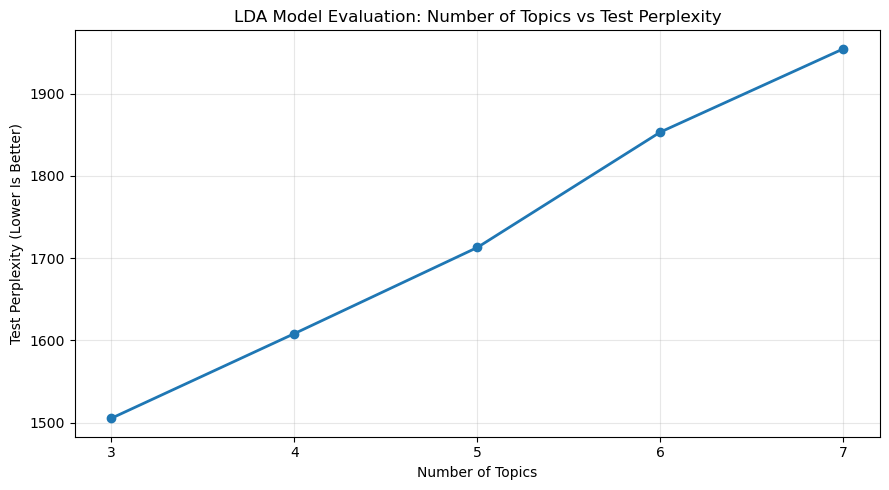


BEST MODEL ACCORDING TO TEST PERPLEXITY
Number of topics: 3
Test perplexity: 1505.21


In [14]:
# STEP 11A: LDA MODEL EVALUATION - COMPARING TOPIC NUMBERS

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.model_selection import train_test_split

# Split the document-term matrix for model evaluation
dtm_train, dtm_test = train_test_split(
    dtm,
    test_size=0.20,
    random_state=42
)

# Compare different numbers of topics
topic_numbers = [3, 4, 5, 6, 7]

evaluation_results = []

for n_topics in topic_numbers:

    print(f"Evaluating LDA model with {n_topics} topics...")

    model = LatentDirichletAllocation(
        n_components=n_topics,
        max_iter=20,
        learning_method="batch",
        random_state=42,
        n_jobs=-1
    )

    # Train using only the training documents
    model.fit(dtm_train)

    # Evaluate on unseen documents
    test_perplexity = model.perplexity(dtm_test)

    evaluation_results.append({
        "Number of Topics": n_topics,
        "Test Perplexity": test_perplexity
    })

# Convert evaluation results into a DataFrame
evaluation_df = pd.DataFrame(evaluation_results)

print("\nLDA MODEL EVALUATION RESULTS")
display(evaluation_df)

# Visualise the relationship between topic number and perplexity
plt.figure(figsize=(9, 5))

plt.plot(
    evaluation_df["Number of Topics"],
    evaluation_df["Test Perplexity"],
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Topics")
plt.ylabel("Test Perplexity (Lower Is Better)")
plt.title("LDA Model Evaluation: Number of Topics vs Test Perplexity")
plt.xticks(topic_numbers)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Identify the model with the lowest test perplexity
best_result = evaluation_df.loc[
    evaluation_df["Test Perplexity"].idxmin()
]

print("\nBEST MODEL ACCORDING TO TEST PERPLEXITY")
print("Number of topics:", int(best_result["Number of Topics"]))
print("Test perplexity:", round(best_result["Test Perplexity"], 2))


### Interpretation of LDA Model Evaluation

To evaluate the Latent Dirichlet Allocation (LDA) model, five configurations containing three, four, five, six and seven topics were compared. The document-term matrix was divided into training (80%) and testing (20%) subsets, allowing model performance to be evaluated on previously unseen reviews.

The three-topic model achieved the lowest test perplexity of 1505.21, followed by the four-topic model at 1608.19. The five-topic model recorded a test perplexity of 1712.99, while the six-topic and seven-topic models produced higher values of 1853.37 and 1954.65, respectively.

The results indicate that increasing the number of topics did not improve predictive performance according to perplexity. Among the evaluated configurations, the three-topic model therefore provided the best statistical fit to the held-out documents.

However, perplexity does not directly measure whether the identified topics are meaningful or useful for decision-making. The previously trained five-topic model distinguished between claims processing, membership administration, pharmacy services, healthcare coverage and positive customer service experiences. These distinctions may offer greater practical value to a medical aid provider seeking to understand specific customer concerns.

Consequently, the five-topic configuration is retained provisionally for further analysis, despite its higher perplexity. The final choice should also consider topic interpretability, overlap and relevance to the client's objectives.

This evaluation demonstrates the importance of considering both quantitative model performance and the practical usefulness of topic modelling results.

TOPIC COUNTS BY PROVIDER


topic_label,Claims and Communication,Hospital Benefits and Coverage,Medication and Pharmacy,Membership and Payments,Positive Customer Service
business_name,,,,,
Affinity Health,89,449,233,232,1179
Bonitas Medical Fund,878,570,111,775,316



TOPIC PERCENTAGES BY PROVIDER


topic_label,Claims and Communication,Hospital Benefits and Coverage,Medication and Pharmacy,Membership and Payments,Positive Customer Service
business_name,,,,,
Affinity Health,4.08,20.58,10.68,10.63,54.03
Bonitas Medical Fund,33.13,21.51,4.19,29.25,11.92


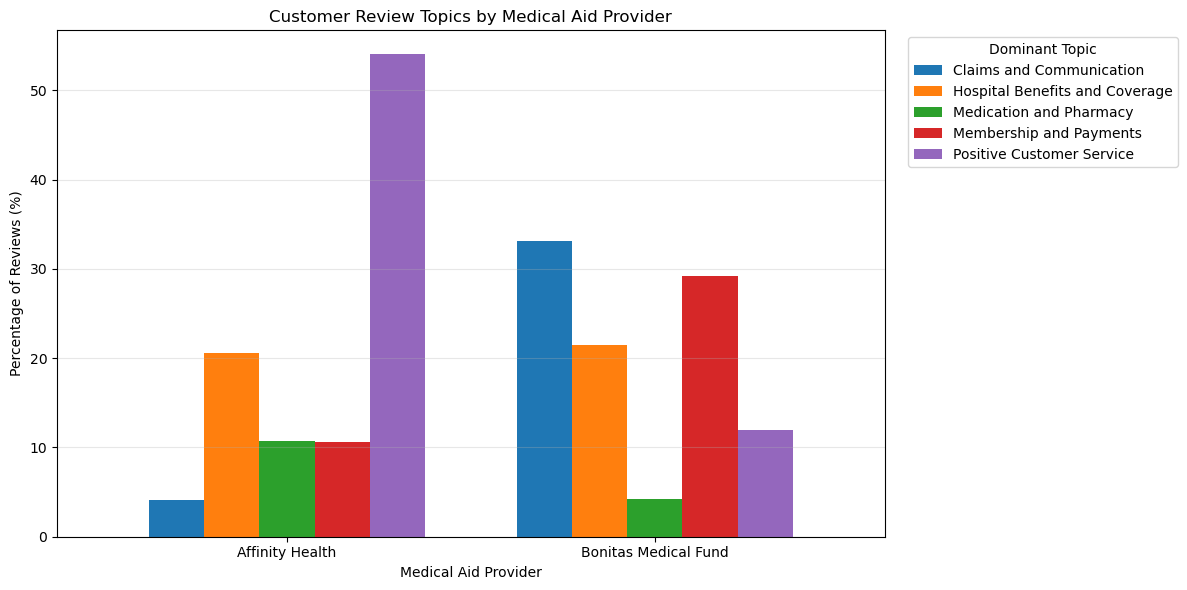

In [15]:
# STEP 11B: TOPIC PREVALENCE BY MEDICAL AID PROVIDER

import pandas as pd
import matplotlib.pyplot as plt

# Obtain topic probabilities from the original five-topic model
topic_probabilities = lda_model.transform(dtm)

# Identify the dominant topic for each review
dominant_topics = topic_probabilities.argmax(axis=1) + 1

# Create a copy of the reviews included in LDA
topic_analysis_df = lda_df.copy()

# Assign dominant topics
topic_analysis_df["dominant_topic"] = dominant_topics

# Define interpretable topic labels
topic_labels = {
    1: "Claims and Communication",
    2: "Membership and Payments",
    3: "Medication and Pharmacy",
    4: "Hospital Benefits and Coverage",
    5: "Positive Customer Service"
}

topic_analysis_df["topic_label"] = (
    topic_analysis_df["dominant_topic"].map(topic_labels)
)

# Count reviews by provider and topic
topic_counts = pd.crosstab(
    topic_analysis_df["business_name"],
    topic_analysis_df["topic_label"]
)

# Calculate within-provider percentages
topic_percentages = (
    topic_counts.div(topic_counts.sum(axis=1), axis=0) * 100
)

print("TOPIC COUNTS BY PROVIDER")
display(topic_counts)

print("\nTOPIC PERCENTAGES BY PROVIDER")
display(topic_percentages.round(2))

# Visualise topic prevalence
ax = topic_percentages.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("Customer Review Topics by Medical Aid Provider")
plt.xlabel("Medical Aid Provider")
plt.ylabel("Percentage of Reviews (%)")
plt.xticks(rotation=0)
plt.legend(
    title="Dominant Topic",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation of Topic Prevalence by Medical Aid Provider

The analysis examined the distribution of five LDA topics across 4,832 customer reviews, comprising 2,182 reviews for Affinity Health and 2,650 for Bonitas Medical Fund. Each review was assigned to the topic with the highest estimated probability, allowing the relative frequency of dominant topics to be compared between the two providers.

For Affinity Health, positive customer service was the most frequently assigned topic, accounting for 54.03% of reviews. Hospital benefits and coverage followed at 20.58%, while medication and pharmacy services accounted for 10.68%. Membership and payments represented 10.63%, and claims and communication accounted for 4.08%.

In contrast, Bonitas Medical Fund reviews were most frequently associated with claims and communication (33.13%), followed by membership and payments (29.25%) and hospital benefits and coverage (21.51%). Positive customer service accounted for 11.92%, while medication and pharmacy services represented 4.19%.

These differences suggest that the two providers have distinct patterns of customer discussion. Claims communication and membership administration appear particularly prominent in Bonitas reviews, while customer service experiences feature more prominently in Affinity Health reviews.

From a business perspective, these findings can help identify areas requiring closer investigation. Bonitas could prioritise examining claims communication and membership administration, while Affinity Health could investigate experiences relating to hospital coverage and medication services.

However, LDA identifies recurring themes rather than determining whether customers are satisfied or dissatisfied. The topic labels are interpretive descriptions based on the model's vocabulary and representative reviews. Consequently, these findings should be considered alongside sentiment analysis before drawing conclusions about customer satisfaction or service quality.

The percentages represent the distribution of dominant topics among the reviews included in this analysis, rather than the prevalence of these experiences among all medical aid members. The comparison is exploratory because the five-topic model was retained for interpretability despite the three-topic model achieving lower test perplexity. Furthermore, differences in the number and characteristics of reviews submitted for each provider may influence the observed patterns. The results should therefore be interpreted as indicators of recurring discussion themes within the dataset, rather than definitive measures of provider performance.

In [16]:
# STEP 12A: IMPORT AND INITIALISE VADER SENTIMENT ANALYSER

import sys
import subprocess
import importlib.util

# Install vaderSentiment only if it is not already available
if importlib.util.find_spec("vaderSentiment") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "vaderSentiment"
    ])

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Initialise the sentiment analyser
sentiment_analyser = SentimentIntensityAnalyzer()

# Test the analyser using example customer reviews
example_reviews = [
    "The customer service was excellent and very helpful.",
    "My medical aid refused to pay my claim. Terrible service!",
    "I contacted the medical aid regarding my membership."
]

for review in example_reviews:
    scores = sentiment_analyser.polarity_scores(review)
    print("Review:", review)
    print("Sentiment scores:", scores)
    print("-" * 60)


Review: The customer service was excellent and very helpful.
Sentiment scores: {'neg': 0.0, 'neu': 0.469, 'pos': 0.531, 'compound': 0.7778}
------------------------------------------------------------
Review: My medical aid refused to pay my claim. Terrible service!
Sentiment scores: {'neg': 0.5, 'neu': 0.5, 'pos': 0.0, 'compound': -0.7177}
------------------------------------------------------------
Review: I contacted the medical aid regarding my membership.
Sentiment scores: {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}
------------------------------------------------------------


In [17]:
# STEP 12B: APPLY VADER SENTIMENT ANALYSIS TO ALL REVIEWS

import pandas as pd

# Use the original reviews to preserve punctuation,
# capitalisation and other sentiment-related information.
text_df["sentiment_text"] = (
    text_df["review_content"]
    .fillna("")
    .astype(str)
)

# Calculate VADER sentiment scores for each review
sentiment_scores = text_df["sentiment_text"].apply(
    sentiment_analyser.polarity_scores
)

# Extract the compound sentiment score
text_df["compound_score"] = sentiment_scores.apply(
    lambda scores: scores["compound"]
)

# Classify sentiment using standard VADER thresholds
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

text_df["sentiment"] = (
    text_df["compound_score"].apply(classify_sentiment)
)

# Display the number of reviews analysed
print("Total reviews analysed:", len(text_df))

# Display sentiment counts
print("\nOVERALL SENTIMENT DISTRIBUTION")
print(text_df["sentiment"].value_counts())

# Display sentiment percentages
print("\nOVERALL SENTIMENT PERCENTAGES")
print(
    text_df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Display examples of classified reviews
print("\nEXAMPLES OF SENTIMENT CLASSIFICATION")

display(
    text_df[
        [
            "business_name",
            "review_content",
            "compound_score",
            "sentiment"
        ]
    ].head(10)
)


Total reviews analysed: 4966

OVERALL SENTIMENT DISTRIBUTION
sentiment
Positive    2801
Negative    1990
Neutral      175
Name: count, dtype: int64

OVERALL SENTIMENT PERCENTAGES
sentiment
Positive    56.40
Negative    40.07
Neutral      3.52
Name: proportion, dtype: float64

EXAMPLES OF SENTIMENT CLASSIFICATION


,business_name,review_content,compound_score,sentiment
25909,Affinity Health,I was extremely dissapointed! I had to go get ...,-0.8580,Negative
25910,Affinity Health,The service of this medical aid is getting so ...,-0.9048,Negative
25911,Affinity Health,WORSE MEDICAL INSURANCE EVER!!! They cover not...,-0.7696,Negative
25912,Affinity Health,USELESS!!! What a waste of money. It's better ...,-0.6496,Negative
25913,Affinity Health,STAY AWAY!! You will spend more time pre-autho...,0.5216,Positive
25914,Affinity Health,To anyone subscribing to this medical insuranc...,-0.8915,Negative
25915,Affinity Health,I signed up for Affinity Health and later on d...,-0.7269,Negative
25916,Affinity Health,"Where do I start? Appalling service, disrespec...",-0.1366,Negative
25917,Affinity Health,Bad I just wish I could cancel this days they ...,-0.9072,Negative
25918,Affinity Health,Please do not apply for this medical insurance...,-0.0258,Neutral


SENTIMENT COUNTS BY PROVIDER


sentiment,Negative,Neutral,Positive
business_name,,,
Affinity Health,564,66,1615
Bonitas Medical Fund,1426,109,1186



SENTIMENT PERCENTAGES BY PROVIDER


sentiment,Negative,Neutral,Positive
business_name,,,
Affinity Health,25.12,2.94,71.94
Bonitas Medical Fund,52.41,4.01,43.59


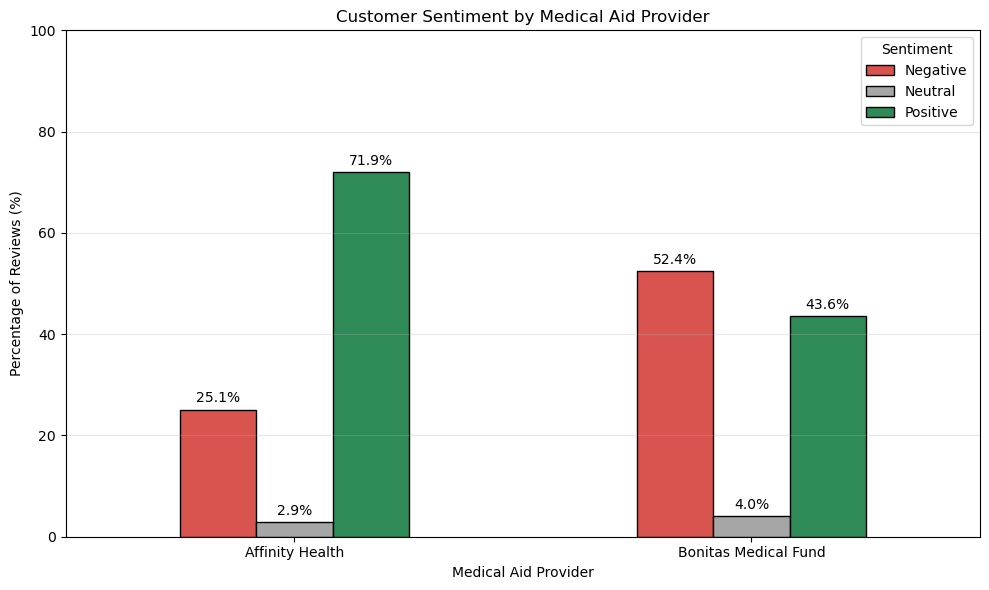

In [18]:
# STEP 12C: SENTIMENT DISTRIBUTION BY MEDICAL AID PROVIDER

import pandas as pd
import matplotlib.pyplot as plt

# Set the order of sentiment categories
sentiment_order = ["Negative", "Neutral", "Positive"]

# Calculate sentiment counts for each provider
sentiment_counts = pd.crosstab(
    text_df["business_name"],
    text_df["sentiment"]
).reindex(columns=sentiment_order, fill_value=0)

# Calculate percentages within each provider
sentiment_percentages = (
    sentiment_counts.div(sentiment_counts.sum(axis=1), axis=0)
    * 100
).round(2)

print("SENTIMENT COUNTS BY PROVIDER")
display(sentiment_counts)

print("\nSENTIMENT PERCENTAGES BY PROVIDER")
display(sentiment_percentages)

# Visualise sentiment distribution
ax = sentiment_percentages.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#D9534F", "#A6A6A6", "#2E8B57"],
    edgecolor="black"
)

plt.title("Customer Sentiment by Medical Aid Provider")
plt.xlabel("Medical Aid Provider")
plt.ylabel("Percentage of Reviews (%)")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.ylim(0, max(100, sentiment_percentages.max().max() + 10))
plt.grid(axis="y", alpha=0.3)

# Display percentages above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


### Interpretation of Sentiment Distribution by Medical Aid Provider

The VADER sentiment analysis classified 4,966 customer reviews into positive, negative and neutral categories. Of these, 2,245 reviews related to Affinity Health and 2,721 to Bonitas Medical Fund.

Affinity Health had a predominantly positive sentiment distribution, with 71.94% of reviews classified as positive, 25.12% as negative and 2.94% as neutral. In comparison, Bonitas Medical Fund had a higher proportion of negative reviews (52.41%) than positive reviews (43.59%), while 4.01% were classified as neutral.

The proportion of positive reviews was 28.35 percentage points higher for Affinity Health than for Bonitas Medical Fund. These differences suggest that the sentiment expressed in the sampled reviews varies substantially between the two providers.

When considered alongside the topic-modelling findings, the results provide a more detailed understanding of customer feedback. For example, claims communication and membership administration were prominent topics in Bonitas reviews, while positive customer service was a prominent topic in Affinity Health reviews. However, topic prevalence and sentiment classification measure different aspects of the text and should not be interpreted as equivalent.

From a business perspective, the findings indicate areas for further investigation. Bonitas Medical Fund could examine negative reviews relating to claims communication, membership administration and payments. Affinity Health could investigate its negative reviews to identify recurring service concerns despite the larger proportion of positive classifications.

These findings should be interpreted cautiously because VADER is a rule-based sentiment analysis method and may misclassify reviews containing sarcasm, mixed opinions or specialised medical insurance terminology. The analysis also reflects the available online reviews rather than a representative survey of all members. Therefore, further evaluation against customer star ratings is required before drawing stronger conclusions about model reliability or customer satisfaction.

In [19]:

# STEP 12D: EVALUATE SENTIMENT USING CUSTOMER STAR RATINGS

import pandas as pd

# Check available columns
print("AVAILABLE COLUMNS")
print(text_df.columns.tolist())

# Examine customer star ratings
print("\nRATING DISTRIBUTION")
print(
    text_df["review_rating"]
    .value_counts(dropna=False)
    .sort_index()
)

# Convert ratings into numeric values
text_df["rating_numeric"] = pd.to_numeric(
    text_df["review_rating"],
    errors="coerce"
)

# Convert customer ratings into sentiment categories
# Ratings 1-2: Negative, 3: Neutral, 4-5: Positive
def rating_to_sentiment(rating):
    if pd.isna(rating):
        return None
    elif rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    elif rating >= 4:
        return "Positive"
    else:
        return None

text_df["rating_sentiment"] = (
    text_df["rating_numeric"].apply(rating_to_sentiment)
)

# Select reviews with valid ratings and VADER predictions
evaluation_sentiment_df = text_df[
    text_df["rating_numeric"].between(1, 5)
    & text_df["rating_sentiment"].notna()
    & text_df["sentiment"].notna()
].copy()

# Display rating-based sentiment distribution
print("\nRATING-BASED SENTIMENT DISTRIBUTION")
print(
    evaluation_sentiment_df["rating_sentiment"]
    .value_counts()
)

# Display VADER sentiment distribution
print("\nVADER SENTIMENT DISTRIBUTION")
print(
    evaluation_sentiment_df["sentiment"]
    .value_counts()
)

# Compare rating-based sentiment with VADER predictions
print("\nRATING-BASED SENTIMENT VS VADER PREDICTIONS")

comparison_table = pd.crosstab(
    evaluation_sentiment_df["rating_sentiment"],
    evaluation_sentiment_df["sentiment"],
    rownames=["Rating-Based Sentiment"],
    colnames=["VADER Prediction"]
)

display(comparison_table)

# Display total number of reviews evaluated
print(
    "\nTOTAL REVIEWS AVAILABLE FOR EVALUATION:",
    len(evaluation_sentiment_df)
)

# Display examples of sentiment predictions
print("\nEXAMPLES OF SENTIMENT EVALUATION")

display(
    evaluation_sentiment_df[
        [
            "business_name",
            "review_rating",
            "rating_sentiment",
            "compound_score",
            "sentiment"
        ]
    ].head(10)
)


AVAILABLE COLUMNS
['created_at', 'business_name', 'review_title', 'review_content', 'review_rating', 'review_length', 'clean_review', 'clean_length', 'sentiment_text', 'compound_score', 'sentiment']

RATING DISTRIBUTION
review_rating
1    1729
2    1085
3     102
4     331
5    1719
Name: count, dtype: int64

RATING-BASED SENTIMENT DISTRIBUTION
rating_sentiment
Negative    2814
Positive    2050
Neutral      102
Name: count, dtype: int64

VADER SENTIMENT DISTRIBUTION
sentiment
Positive    2801
Negative    1990
Neutral      175
Name: count, dtype: int64

RATING-BASED SENTIMENT VS VADER PREDICTIONS


VADER Prediction,Negative,Neutral,Positive
Rating-Based Sentiment,,,
Negative,1909,99,806
Neutral,38,8,56
Positive,43,68,1939



TOTAL REVIEWS AVAILABLE FOR EVALUATION: 4966

EXAMPLES OF SENTIMENT EVALUATION


,business_name,review_rating,rating_sentiment,compound_score,sentiment
25909,Affinity Health,1,Negative,-0.8580,Negative
25910,Affinity Health,1,Negative,-0.9048,Negative
25911,Affinity Health,1,Negative,-0.7696,Negative
25912,Affinity Health,1,Negative,-0.6496,Negative
25913,Affinity Health,1,Negative,0.5216,Positive
25914,Affinity Health,1,Negative,-0.8915,Negative
25915,Affinity Health,1,Negative,-0.7269,Negative
25916,Affinity Health,1,Negative,-0.1366,Negative
25917,Affinity Health,1,Negative,-0.9072,Negative
25918,Affinity Health,1,Negative,-0.0258,Neutral


VADER SENTIMENT CLASSIFICATION PERFORMANCE
Accuracy: 0.7765
Macro Precision: 0.5658
Macro Recall: 0.5676
Macro F1-Score: 0.5506

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.96      0.68      0.79      2814
     Neutral       0.05      0.08      0.06       102
    Positive       0.69      0.95      0.80      2050

    accuracy                           0.78      4966
   macro avg       0.57      0.57      0.55      4966
weighted avg       0.83      0.78      0.78      4966



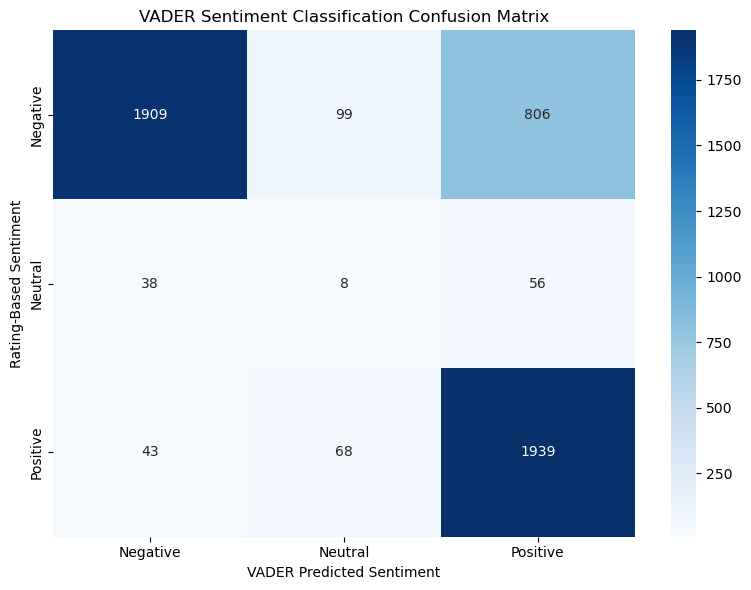

In [20]:
# STEP 12E: EVALUATE VADER SENTIMENT CLASSIFICATION

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Define reference labels and predicted labels
y_true = evaluation_sentiment_df["rating_sentiment"]
y_pred = evaluation_sentiment_df["sentiment"]

sentiment_labels = ["Negative", "Neutral", "Positive"]

# Calculate classification performance metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    labels=sentiment_labels,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    labels=sentiment_labels,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    labels=sentiment_labels,
    average="macro",
    zero_division=0
)

print("VADER SENTIMENT CLASSIFICATION PERFORMANCE")
print("Accuracy:", round(accuracy, 4))
print("Macro Precision:", round(precision, 4))
print("Macro Recall:", round(recall, 4))
print("Macro F1-Score:", round(f1, 4))

# Display detailed classification results
print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        y_pred,
        labels=sentiment_labels,
        zero_division=0
    )
)

# Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=sentiment_labels
)

# Visualise confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sentiment_labels,
    yticklabels=sentiment_labels
)

plt.title("VADER Sentiment Classification Confusion Matrix")
plt.xlabel("VADER Predicted Sentiment")
plt.ylabel("Rating-Based Sentiment")
plt.tight_layout()
plt.show()


### Interpretation of VADER Sentiment Classification Performance

VADER sentiment classification was evaluated against sentiment categories derived from customer star ratings for 4,966 reviews. Ratings of one or two stars were treated as negative, three stars as neutral, and four or five stars as positive.

The analysis produced an overall classification agreement of 77.65%, with macro precision of 56.58%, macro recall of 56.76%, and a macro F1-score of 55.06%. The difference between overall agreement and macro F1-score indicates that VADER performed unevenly across the three sentiment categories.

For negative sentiment, VADER achieved precision of 0.96, recall of 0.68, and an F1-score of 0.79. This indicates that most reviews classified as negative were also negatively rated, although the model failed to identify a substantial proportion of negatively rated reviews. In particular, 806 reviews with negative rating-based labels were classified as positive by VADER.

Positive sentiment achieved precision of 0.69, recall of 0.95, and an F1-score of 0.80. This suggests that VADER identified most positively rated reviews but also assigned positive classifications to some reviews with lower ratings.

Neutral sentiment showed the weakest performance, with precision of 0.05, recall of 0.08, and an F1-score of 0.06. Only eight of the 102 reviews assigned neutral rating-based labels were classified as neutral by VADER. The small number of neutral reviews and differences between star ratings and written sentiment may have contributed to this result.

These findings demonstrate both the usefulness and limitations of VADER for analysing medical aid customer reviews. Although VADER provides a practical method for automatically classifying large volumes of text, it may struggle with mixed opinions, sarcasm and specialised healthcare terminology.

A further limitation is that customer star ratings were used as reference labels rather than independently annotated sentiment. A low rating may accompany text containing positive language, and a review may express several different opinions. Consequently, the evaluation measures agreement with rating-derived sentiment rather than definitive accuracy against verified sentiment labels.

For the medical aid client, VADER can support an initial assessment of customer sentiment, but its classifications should be interpreted cautiously. Further investigation of disagreements between star ratings and predicted sentiment would help determine whether the model is suitable for identifying customer dissatisfaction reliably.

SENTIMENT CLASSIFICATION ERROR ANALYSIS
Total reviews evaluated: 4966
Total disagreements: 1110
Disagreement rate: 22.35 %

TYPES OF SENTIMENT DISAGREEMENT


VADER Prediction,Negative,Neutral,Positive
Rating-Based Sentiment,,,
Negative,0,99,806
Neutral,38,0,56
Positive,43,68,0



NEGATIVE RATINGS CLASSIFIED AS POSITIVE
Number of reviews: 806


,business_name,review_rating,review_content,compound_score,sentiment
25913,Affinity Health,1,STAY AWAY!! You will spend more time pre-autho...,0.5216,Positive
25919,Affinity Health,1,"First of all, I would not recommend any insura...",0.7127,Positive
25921,Affinity Health,1,"So following protocol paying upfront, having a...",0.9174,Positive
25922,Affinity Health,1,Great Customers care services The Likes of Tin...,0.7642,Positive
25923,Affinity Health,1,I am currently sick and trying to see a Dr .An...,0.3715,Positive



POSITIVE RATINGS CLASSIFIED AS NEGATIVE
Number of reviews: 43


,business_name,review_rating,review_content,compound_score,sentiment
26802,Affinity Health,4,Although my experience at Affinity Health was ...,-0.4588,Negative
26984,Affinity Health,4,Had a problem with Affinity Health not paying ...,-0.3400,Negative
27018,Affinity Health,4,I have had a problem with accounts at Affinity...,-0.2144,Negative
27029,Affinity Health,4,"<p>I am new to Affinity Health, and had my fir...",-0.9537,Negative
27047,Affinity Health,4,<p>Got great service this morning. Called the ...,-0.0552,Negative



SENTIMENT DISAGREEMENT BY PROVIDER


,Total_Reviews,Disagreements,Disagreement_Rate
business_name,,,
Affinity Health,2245,330,14.70
Bonitas Medical Fund,2721,780,28.67


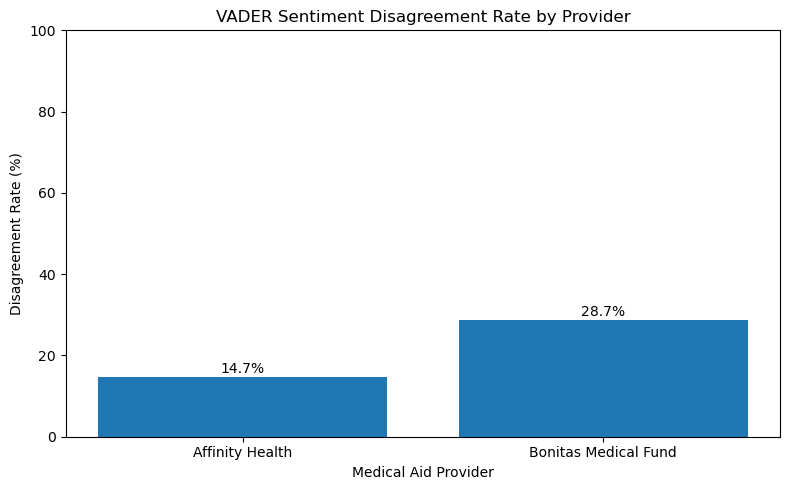

In [21]:
# STEP 12F: SENTIMENT CLASSIFICATION ERROR ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt

# Identify disagreements between ratings and VADER predictions
error_df = evaluation_sentiment_df[
    evaluation_sentiment_df["rating_sentiment"]
    != evaluation_sentiment_df["sentiment"]
].copy()

# Calculate overall disagreement
total_reviews = len(evaluation_sentiment_df)
total_errors = len(error_df)
error_rate = (total_errors / total_reviews) * 100

print("SENTIMENT CLASSIFICATION ERROR ANALYSIS")
print("Total reviews evaluated:", total_reviews)
print("Total disagreements:", total_errors)
print("Disagreement rate:", round(error_rate, 2), "%")

# Count different types of disagreement
error_summary = pd.crosstab(
    error_df["rating_sentiment"],
    error_df["sentiment"],
    rownames=["Rating-Based Sentiment"],
    colnames=["VADER Prediction"]
)

print("\nTYPES OF SENTIMENT DISAGREEMENT")
display(error_summary)

# Examine negative-rated reviews classified as positive
negative_to_positive = error_df[
    (error_df["rating_sentiment"] == "Negative")
    & (error_df["sentiment"] == "Positive")
]

print("\nNEGATIVE RATINGS CLASSIFIED AS POSITIVE")
print("Number of reviews:", len(negative_to_positive))

display(
    negative_to_positive[
        [
            "business_name",
            "review_rating",
            "review_content",
            "compound_score",
            "sentiment"
        ]
    ].head(5)
)

# Examine positive-rated reviews classified as negative
positive_to_negative = error_df[
    (error_df["rating_sentiment"] == "Positive")
    & (error_df["sentiment"] == "Negative")
]

print("\nPOSITIVE RATINGS CLASSIFIED AS NEGATIVE")
print("Number of reviews:", len(positive_to_negative))

display(
    positive_to_negative[
        [
            "business_name",
            "review_rating",
            "review_content",
            "compound_score",
            "sentiment"
        ]
    ].head(5)
)

# Calculate disagreement rates for each provider
provider_errors = (
    evaluation_sentiment_df
    .assign(
        disagreement=lambda df:
        df["rating_sentiment"] != df["sentiment"]
    )
    .groupby("business_name")
    .agg(
        Total_Reviews=("disagreement", "size"),
        Disagreements=("disagreement", "sum"),
        Disagreement_Rate=("disagreement", "mean")
    )
)

provider_errors["Disagreement_Rate"] *= 100

print("\nSENTIMENT DISAGREEMENT BY PROVIDER")
display(provider_errors.round(2))

# Visualise disagreement rates by provider
plt.figure(figsize=(8, 5))

bars = plt.bar(
    provider_errors.index,
    provider_errors["Disagreement_Rate"]
)

plt.title("VADER Sentiment Disagreement Rate by Provider")
plt.xlabel("Medical Aid Provider")
plt.ylabel("Disagreement Rate (%)")
plt.ylim(0, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()



### Interpretation of Sentiment Classification Error Analysis

The error analysis compared VADER sentiment predictions with sentiment categories derived from customer review ratings. Of the 4,966 reviews evaluated, 1,110 (22.35%) showed disagreement between the two classification methods.

The largest source of disagreement involved 806 reviews with negative ratings that VADER classified as positive. This suggests that VADER may struggle to interpret certain customer complaints, particularly reviews containing mixed sentiments, contextual expressions or negative statements alongside positive words.

The disagreement rate differed between providers. Bonitas Medical Fund recorded a disagreement rate of 28.67%, compared with 14.70% for Affinity Health. This indicates that VADER predictions were less consistent with rating-derived sentiment labels for the Bonitas reviews.

These results highlight an important limitation of lexicon-based sentiment analysis. Although VADER provides a practical and computationally efficient approach to classifying customer reviews, its predictions should not be treated as completely reliable without further validation.

Importantly, review ratings are used as reference labels rather than independently verified sentiment classifications. Consequently, disagreements do not necessarily represent confirmed model errors.

For the medical aid client, the findings suggest that automated sentiment analysis can assist with identifying broad customer satisfaction patterns, but reviews involving potentially serious complaints should also be examined manually.


In [22]:
# STEP 12G: MANUAL EXAMINATION OF SENTIMENT DISAGREEMENTS

# Display complete text for five negatively rated reviews
# that VADER classified as positive

for index, row in negative_to_positive.head(5).iterrows():
    print("=" * 80)
    print("Review index:", index)
    print("Provider:", row["business_name"])
    print("Star rating:", row["review_rating"])
    print("VADER compound score:", row["compound_score"])
    print("VADER sentiment:", row["sentiment"])
    print("\nFull review:")
    print(row["review_content"])
    print()


Review index: 25913
Provider: Affinity Health
Star rating: 1
VADER compound score: 0.5216
VADER sentiment: Positive

Full review:
STAY AWAY!! You will spend more time pre-authorizing almost everything and money on airtime than the scheme is worth. I have ZERO confidence that this company will pay any big emergency or medical-related bill that I may have in the future!!

Review index: 25919
Provider: Affinity Health
Star rating: 1
VADER compound score: 0.7127
VADER sentiment: Positive

Full review:
First of all, I would not recommend any insurance company for health cover - they simply don't have the skill or empathy to deal with your situation. They collect your premium every month but the moment you need basic care they have a 1000 questions and objections. Out of a service perspective they really great but that's about it. They refused to pay a basic blood test and when I ask them to cancel my cover, they did not even try to retain me.

Review index: 25921
Provider: Affinity Health
S

### Interpretation of Manual Sentiment Disagreement Analysis

Five customer reviews with one-star ratings that VADER classified as positive were examined manually to investigate possible reasons for disagreement between the two sentiment measures.

The reviews expressed dissatisfaction with medical aid services, including pre-authorisation requirements, claim reimbursements, medicine benefits, communication and access to healthcare assistance. Despite these concerns, VADER assigned positive compound scores ranging from 0.3715 to 0.9174.

The examples suggest that VADER may struggle to interpret the overall meaning of certain complaints when they contain positive expressions, formal communication or a mixture of positive and negative statements. For example, one review included praise for customer care while also expressing dissatisfaction with medicine benefits. Another contained a formal response from the provider within a complaint about reimbursement.

These findings illustrate a limitation of lexicon-based sentiment analysis: the presence of positively weighted words does not necessarily indicate that a customer is satisfied with the service being discussed.

However, the five reviews were selected specifically because their classifications disagreed with their ratings. They therefore illustrate potential classification problems rather than providing a representative estimate of VADER's performance.

For the medical aid client, this suggests that automated sentiment classifications should be supplemented by manual examination, particularly for complaints involving claims, reimbursements and access to healthcare services.

## Step 13: Consolidated Findings and Business Implications

### 13.1 Purpose of the Analysis

This analysis examined customer reviews relating to Affinity Health and Bonitas Medical Fund to identify recurring discussion topics and assess customer sentiment.

Latent Dirichlet Allocation (LDA) was used to identify underlying themes in the review text, while VADER sentiment analysis was used to classify reviews as positive, negative or neutral.

### 13.2 Topic Modelling Findings

The topic analysis identified themes relating to claims and communication, hospital benefits and coverage, medication and pharmacy services, membership and payments, and positive customer service.

For Affinity Health, positive customer service was the most frequently assigned topic (54.03%). For Bonitas Medical Fund, claims and communication was the most frequent topic (33.13%), followed by membership and payments (29.25%).

These findings indicate differences in the subjects discussed by reviewers. However, topic prevalence alone does not establish whether customers were satisfied or dissatisfied with a particular service.

### 13.3 Sentiment Analysis Findings

VADER classified 56.40% of the 4,966 reviews as positive, 40.07% as negative and 3.52% as neutral.

Affinity Health had a higher proportion of positive sentiment classifications (71.94%) than Bonitas Medical Fund (43.59%).

These percentages describe the analysed review sample and should not be interpreted as representative measures of overall customer satisfaction.

### 13.4 Model Evaluation

The sentiment classification achieved an accuracy of 77.65% when compared with sentiment labels derived from review ratings.

However, the macro F1-score was 0.5506, indicating uneven performance across sentiment categories. Neutral reviews were particularly difficult to classify accurately.

Further error analysis identified disagreements in 22.35% of reviews. This demonstrates the importance of evaluating model performance rather than relying exclusively on automated sentiment predictions.

A manual examination of five one-star reviews classified as positive by VADER provided further evidence of the model's limitations. These reviews contained complaints about authorisation, reimbursement, medicine benefits and access to healthcare services. The findings suggest that positive wording within an otherwise negative review can contribute to misleading sentiment classifications. However, the five selected examples do not establish the frequency of this problem across the entire dataset.

LDA model evaluation compared configurations containing three to seven topics using test perplexity on held-out reviews. The three-topic model achieved the lowest perplexity (1,505.21), indicating the best predictive performance among the evaluated configurations. However, the five-topic model was retained for the exploratory business analysis because its themes provided more specific distinctions between claims, membership administration, healthcare coverage, pharmacy services and customer service. This decision prioritised practical interpretability over the lowest perplexity and should therefore be regarded as a modelling trade-off rather than evidence that the five-topic model was statistically superior.

### 13.5 Business Implications

The findings suggest that medical aid providers could use text analytics to monitor recurring customer concerns and identify reviews requiring further investigation.

For Bonitas Medical Fund, claims communication and membership-related processes warrant closer examination within the analysed review sample.

For Affinity Health, the prominence of positive customer service discussions may provide an opportunity to investigate which service experiences customers value.

Both providers should combine automated analysis with manual review of important complaints before making operational decisions.

As a practical next step, medical aid providers could prioritise the manual examination of negatively rated reviews that automated sentiment analysis classifies as positive. They could also monitor recurring topics relating to claims, authorisations and membership processes, using the findings to guide further investigation rather than treating topic frequencies as confirmed service failures.

### 13.6 Limitations

The analysis is limited to the available online reviews, which may not represent the broader membership populations of either provider.

LDA topics require human interpretation, and VADER may misclassify reviews containing complex language, mixed sentiments or contextual expressions.

Furthermore, rating-derived sentiment labels provide an imperfect reference for evaluating classification performance.